# Экзаменационная задача №05. Расчёт стоимости разработки по COCOMO II

**Дисциплина:** Экономика информатизации, лекция №6
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №05: РАСЧЁТ СТОИМОСТИ РАЗРАБОТКИ ПО COCOMO II
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №6)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Нужно обосновать стоимость разработки госсистемы «Единый портал поддержки предпринимателей». Ошибка в оценке дорого стоит:
если цену занизить, подрядчик сорвёт контракт, если завысить, бюджет потратят впустую.
Считаем по модели **COCOMO II (Post-Architecture)**: она связывает размер программы, особенности проекта и трудоёмкость.
Результат сравниваем с методикой г. Москвы.

**Цель:** посчитать трудоёмкость, срок и полную стоимость разработки с НДС и объяснить, почему результат отличается
от методики г. Москвы.

Тема лекции №6: функциональные точки и KLOC, факторы масштаба (SF) и отрицательный эффект масштаба, множители трудоёмкости (EM).

## 2. Исходные данные

In [2]:
# 1.1. Размер системы
FP = 450              # функциональные точки
K_lang = 54           # строк кода на 1 FP для C#
reuse = 0.20          # доля повторного использования

# 1.2. Факторы масштаба (SF) и множители трудоёмкости (EM) — из условия
SF = {"PREC": 4, "FLEX": 3, "RESL": 3, "TEAM": 4, "PMAT": 3}
EM = {"RELY": 1.15, "DATA": 1.00, "CPLX": 1.15, "TIME": 1.00, "STOR": 1.00, "ACAP": 1.15, "PCAP": 1.10,
      "PCON": 1.00, "APEX": 1.00, "PEXP": 1.00, "LTEX": 1.00, "TOOL": 1.00, "SITE": 1.00, "SCED": 1.00, "RUSE": 1.10}

# 1.3. Параметры модели и стоимости
A, B_base = 2.94, 0.91
pm_cost = 220_000     # стоимость человеко-месяца, руб.
overhead = 0.25       # накладные расходы, доля от ФОТ
VAT = 0.20
display(pd.DataFrame({"SF": SF}).T)
pd.DataFrame({"EM": EM}).T

,PREC,FLEX,RESL,TEAM,PMAT
SF,4,3,3,4,3


,RELY,DATA,CPLX,TIME,STOR,ACAP,PCAP,PCON,APEX,PEXP,LTEX,TOOL,SITE,SCED,RUSE
EM,1.15,1.00,1.15,1.00,1.00,1.15,1.10,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.10


## 3. Математическая модель

$$KLOC = \frac{FP\cdot K_п}{1000}\,(1-k_{reuse}),\qquad B = B_{base}+0{,}01\sum SF_j,\qquad EM_{total}=\prod_{i=1}^{15}EM_i$$
$$Effort = A\cdot KLOC^{B}\cdot EM_{total}\ \ [\text{чел.-мес.}],\qquad TDEV = 2{,}5\cdot Effort^{0{,}35}\ \ [\text{мес.}]$$
$$C_{прям}=Effort\cdot C_{ч.-м.},\quad C_{накл}=0{,}25\,C_{прям},\quad C_{без\,НДС}=C_{прям}+C_{накл},\quad C_{с\,НДС}=1{,}2\,C_{без\,НДС}$$

Если $B>1$, эффект масштаба отрицательный: система в 2 раза больше требует больше чем в 2 раза больше труда,
потому что растут затраты на общение и интеграцию.

## 4. Реализация расчёта

In [3]:
# 2.1. Размер
KLOC_raw = FP * K_lang / 1000
KLOC = KLOC_raw * (1 - reuse)
# 2.2. Коэффициент масштаба
sum_SF = sum(SF.values()); B = B_base + 0.01 * sum_SF
# 2.3. Произведение множителей
EM_total = math.prod(EM.values())
# 2.4. Трудоёмкость и длительность
effort = A * KLOC ** B * EM_total
effort_nominal = A * KLOC ** B          # без поправочных множителей
TDEV = 2.5 * effort ** 0.35
team = effort / TDEV
print(f"KLOC = {FP}·{K_lang}/1000·(1−{reuse}) = {KLOC_raw:.2f}·{1-reuse} = {KLOC:.2f} KLOC")
print(f"ΣSF = {sum_SF};  B = {B_base} + 0.01·{sum_SF} = {B:.2f}")
print("EM_total = " + " · ".join(f"{v:.2f}" for v in EM.values() if v != 1) + f" = {EM_total:.4f}")
print(f"KLOC^B = {KLOC:.2f}^{B:.2f} = {KLOC**B:.2f}")
print(f"Effort = {A}·{KLOC**B:.2f}·{EM_total:.4f} = {effort:.1f} чел.-мес. (номинально без EM: {effort_nominal:.1f})")
print(f"TDEV = 2.5·{effort:.1f}^0.35 = {TDEV:.1f} мес.;  средняя команда = {team:.1f} чел.")

KLOC = 450·54/1000·(1−0.2) = 24.30·0.8 = 19.44 KLOC
ΣSF = 17;  B = 0.91 + 0.01·17 = 1.08
EM_total = 1.15 · 1.15 · 1.15 · 1.10 · 1.10 = 1.8403
KLOC^B = 19.44^1.08 = 24.65
Effort = 2.94·24.65·1.8403 = 133.4 чел.-мес. (номинально без EM: 72.5)
TDEV = 2.5·133.4^0.35 = 13.9 мес.;  средняя команда = 9.6 чел.


In [4]:
# 2.5. Стоимость
direct = effort * pm_cost
over = direct * overhead
cost_net = direct + over
cost_vat = cost_net * (1 + VAT)
cost = pd.DataFrame({"Статья": ["Прямые затраты (Effort × 220 000)", "Накладные расходы (25%)", "Итого без НДС", "НДС 20%", "Итого с НДС"],
                     "Сумма, руб.": [direct, over, cost_net, cost_vat - cost_net, cost_vat]})
cost["Сумма, млн руб."] = cost["Сумма, руб."] / 1e6
cost

,Статья,"Сумма, руб.","Сумма, млн руб."
0,Прямые затраты (Effort × 220 000),29 338 699.85,29.34
1,Накладные расходы (25%),7 334 674.96,7.33
2,Итого без НДС,36 673 374.81,36.67
3,НДС 20%,7 334 674.96,7.33
4,Итого с НДС,44 008 049.77,44.01


### 4.1. Сравнение с методикой г. Москвы (лекция №19)

Методика устроена так же, как COCOMO, но со своими коэффициентами: $ОТр = 5{,}17\cdot РР^{0{,}94}\cdot\prod МТ_i$, где
$РР = ФТ\cdot К_п/1000$. Повторное использование здесь не вычитается из размера, оно учитывается через коэффициенты.
Коэффициенты для портала: МТ1 = 1,15 (критичная ИС, как RELY), МТ2 = 1,00, МТ3 = 1,00 (10–20 интеграций),
МТ4 = 1,00 (ИС обеспечения деятельности), МТ5 = 1,00, МТ6 = 1,00, МТ7 = 1,04 (создание новой ИС).
Стоимость человеко-месяца по методике: $В_{ср}=ЗПБ_{2015}\cdot К_{пер}\cdot(1+Р)/К_3 = 78\,300\cdot1{,}064\cdot1{,}10/0{,}65$,
коэффициент квалификации $К_{кв}=0{,}874$ (из примера методики).

In [5]:
MT = {"МТ1": 1.15, "МТ2": 1.00, "МТ3": 1.00, "МТ4": 1.00, "МТ5": 1.00, "МТ6": 1.00, "МТ7": 1.04}
MT_total = math.prod(MT.values())
RR = FP * K_lang / 1000
OTr = 5.17 * RR ** 0.94 * MT_total
OTr_reuse = 5.17 * KLOC ** 0.94 * MT_total           # если учесть повторное использование так же, как в COCOMO
V_sr = 78_300 * 1.064 * 1.10 / 0.65
Kkv = 0.874
moscow_net = OTr * V_sr * Kkv
comp = pd.DataFrame({
    "Показатель": ["Размер, тыс. строк", "Показатель степени", "Произведение поправочных коэфф.", "Трудозатраты, чел.-мес.",
                   "Стоимость чел.-мес., руб.", "Стоимость без НДС, млн руб.", "Стоимость с НДС, млн руб."],
    "COCOMO II": [KLOC, B, EM_total, effort, pm_cost * (1 + overhead), cost_net / 1e6, cost_vat / 1e6],
    "Методика г. Москвы": [RR, 0.94, MT_total, OTr, V_sr * Kkv, moscow_net / 1e6, moscow_net * 1.2 / 1e6]})
print(f"Методика с учётом 20% повторного использования: ОТр = {OTr_reuse:.1f} чел.-мес.")
comp

Методика с учётом 20% повторного использования: ОТр = 100.6 чел.-мес.


,Показатель,COCOMO II,Методика г. Москвы
0,"Размер, тыс. строк",19.44,24.30
1,Показатель степени,1.08,0.94
2,Произведение поправочных коэфф.,1.84,1.20
3,"Трудозатраты, чел.-мес.",133.36,124.08
4,"Стоимость чел.-мес., руб.",275 000.00,123 223.67
5,"Стоимость без НДС, млн руб.",36.67,15.29
6,"Стоимость с НДС, млн руб.",44.01,18.35


### 4.2. Анализ чувствительности

Отдельно проверим два спорных места: (1) **ACAP = 1,15** при описании «высокие способности аналитиков». По шкале COCOMO II
высокие способности *снижают* трудоёмкость (High = 0,85). (2) Размер может быть оценён с ошибкой ±20 %
(на ранних стадиях функциональные точки считают неточно).

In [6]:
def cocomo_cost(fp=FP, reuse_=reuse, em_over=None, sf_over=None):
    em = dict(EM, **(em_over or {})); sf = dict(SF, **(sf_over or {}))
    kloc = fp * K_lang / 1000 * (1 - reuse_)
    eff = A * kloc ** (B_base + 0.01 * sum(sf.values())) * math.prod(em.values())
    return eff, eff * pm_cost * (1 + overhead) * (1 + VAT) / 1e6

cases = {"Базовый расчёт": {}, "ACAP = 0.85 (High по шкале COCOMO)": {"em_over": {"ACAP": 0.85}},
         "ACAP 0.85, PCAP 1.00": {"em_over": {"ACAP": 0.85, "PCAP": 1.00}},
         "Размер −20% (360 FP)": {"fp": 360}, "Размер +20% (540 FP)": {"fp": 540},
         "Без повторного использования": {"reuse_": 0.0}, "RUSE = 1.00 (не требуется)": {"em_over": {"RUSE": 1.0}},
         "PMAT = 1 (зрелые процессы)": {"sf_over": {"PMAT": 1}}}
sens = pd.DataFrame([{"Сценарий": k, "Effort, чел.-мес.": cocomo_cost(**v)[0], "Стоимость с НДС, млн": cocomo_cost(**v)[1]}
                     for k, v in cases.items()]).set_index("Сценарий")
sens["Δ к базе, %"] = (sens["Стоимость с НДС, млн"] / sens.iloc[0]["Стоимость с НДС, млн"] - 1) * 100
sens.round(1)

,"Effort, чел.-мес.","Стоимость с НДС, млн","Δ к базе, %"
Сценарий,,,
Базовый расчёт,133.40,44.00,0.00
ACAP = 0.85 (High по шкале COCOMO),98.60,32.50,-26.10
"ACAP 0.85, PCAP 1.00",89.60,29.60,-32.80
Размер −20% (360 FP),104.80,34.60,-21.40
Размер +20% (540 FP),162.40,53.60,21.80
Без повторного использования,169.70,56.00,27.30
RUSE = 1.00 (не требуется),121.20,40.00,-9.10
PMAT = 1 (зрелые процессы),125.70,41.50,-5.80


## 5. Визуализация результатов

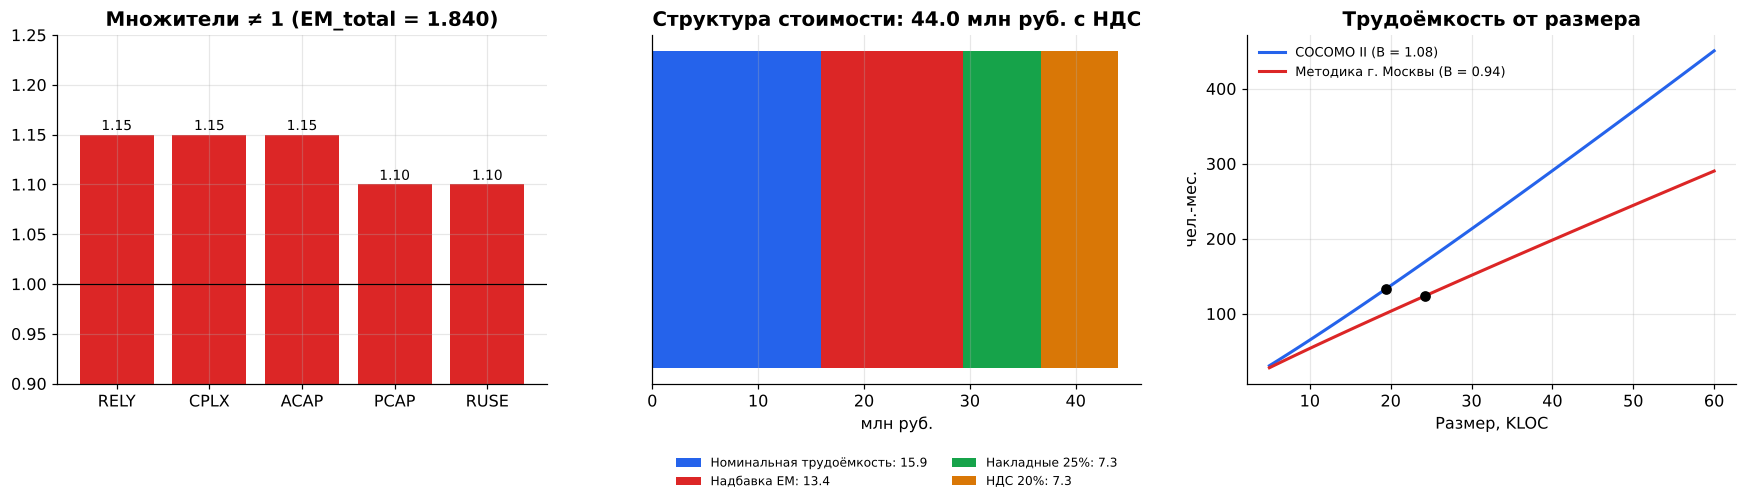

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
ax = axes[0]
em_nontrivial = {k: v for k, v in EM.items() if v != 1}
bars = ax.bar(em_nontrivial.keys(), em_nontrivial.values(), color=PALETTE[1]); bar_labels(ax, bars, "{:.2f}")
ax.axhline(1, color="black", lw=0.8); ax.set_ylim(0.9, 1.25); ax.set_title(f"Множители ≠ 1 (EM_total = {EM_total:.3f})")
ax = axes[1]
parts = [effort_nominal * pm_cost / 1e6, direct / 1e6 - effort_nominal * pm_cost / 1e6, over / 1e6, (cost_vat - cost_net) / 1e6]
lbl = ["Номинальная\nтрудоёмкость", "Надбавка EM", "Накладные 25%", "НДС 20%"]
left = 0
for p, l, c in zip(parts, lbl, PALETTE):
    ax.barh([0], [p], left=left, color=c, label=f"{l.replace(chr(10), ' ')}: {p:.1f}"); left += p
ax.set_yticks([]); ax.set_xlabel("млн руб."); ax.set_title(f"Структура стоимости: {cost_vat/1e6:.1f} млн руб. с НДС")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
ax = axes[2]
kl = np.linspace(5, 60, 100)
ax.plot(kl, A * kl ** B * EM_total, lw=2, label=f"COCOMO II (B = {B:.2f})")
ax.plot(kl, 5.17 * kl ** 0.94 * MT_total, lw=2, label="Методика г. Москвы (B = 0.94)")
ax.scatter([KLOC, RR], [effort, OTr], color="black", zorder=3)
ax.set_xlabel("Размер, KLOC"); ax.set_ylabel("чел.-мес."); ax.set_title("Трудоёмкость от размера"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

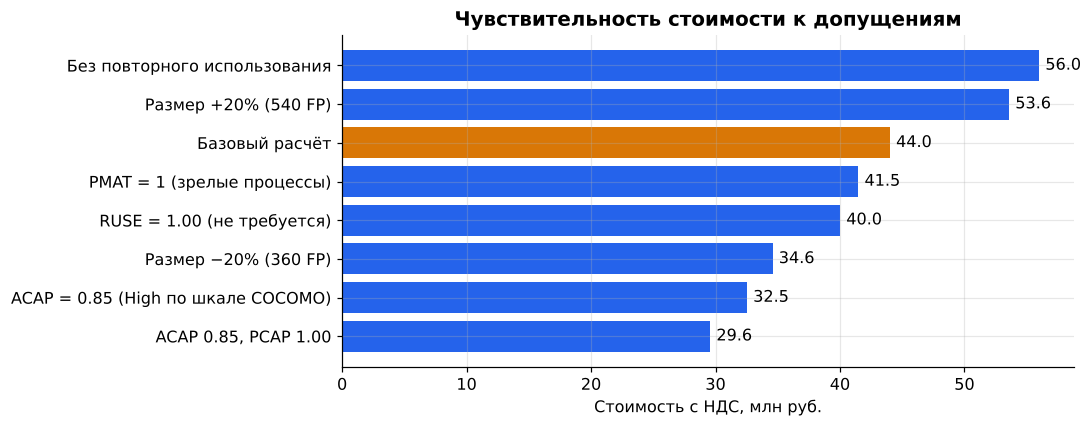

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
s = sens.sort_values("Стоимость с НДС, млн")
bars = ax.barh(s.index, s["Стоимость с НДС, млн"], color=[PALETTE[0] if i != "Базовый расчёт" else PALETTE[3] for i in s.index])
for b, v in zip(bars, s["Стоимость с НДС, млн"]):
    ax.text(v + 0.5, b.get_y() + b.get_height() / 2, f"{v:.1f}", va="center")
ax.set_xlabel("Стоимость с НДС, млн руб."); ax.set_title("Чувствительность стоимости к допущениям")
plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

- Размер с учётом повторного использования **19,44 KLOC**. $B = 1{,}08$, то есть отрицательный эффект масштаба умеренный.
- Множители увеличивают трудоёмкость в **1,84 раза** ($1{,}15^3\cdot1{,}10^2$). Больше всего дают надёжность,
  сложность алгоритмов и требование повторного использования (RUSE).
- Трудоёмкость около **133 чел.-мес.**, срок около **13,9 мес.**, в среднем 9,6 человека в команде.
- Стоимость: прямые затраты 29,3 млн руб., с накладными 36,7 млн руб., **с НДС около 44,0 млн руб.**
- **Сравнение с методикой г. Москвы.** Трудозатраты почти такие же: около 124 чел.-мес. (на 7 % меньше; с учётом повторного
  использования около 101). А цена ниже примерно в 2,4 раза: 18,4 млн руб. с НДС против 44,0 млн. Причина в ставке:
  человеко-месяц по методике стоит около 123 тыс. руб., а в рыночном расчёте 220 тыс. руб. плюс 25 % накладных.
  То есть трудоёмкость совпадает, а разница в цене почти целиком из-за ставки оплаты труда.

  | Причина | COCOMO II | Методика г. Москвы |
  |---|---|---|
  | Калибровка | A = 2,94, B зависит от SF (1,08) | A = 5,17, B = 0,94 (под госпроекты Москвы) |
  | Факторы | 5 SF + 15 EM | 7 коэффициентов МТ |
  | Повторное использование | прямо уменьшает размер (−20 %) | косвенно, через МТ7 и РР |
  | Стоимость труда | рыночная ставка 220 тыс. руб. + 25 % накладных | норматив ЗПБ-2015 × индексы, К₃ = 0,65, квалификация |
  | Прибыль | не выделена | рентабельность 5–10 % |
- **Качество исходных данных.** ACAP = 1,15 не сходится с описанием «высокие способности аналитиков»: по шкале COCOMO II
  это уровень *Low*. При правильном ACAP = 0,85 стоимость падает примерно на 26 %. Один неверный множитель меняет цену
  на десятки процентов, поэтому каждый множитель нужно подтверждать документами.

## 7. Выводы и рекомендации

1. Оценка по COCOMO II: **около 133 чел.-мес., 14 мес., 44,0 млн руб. с НДС**.
2. Для госзакупки (НМЦК) основной расчёт делать по **методике г. Москвы**, а COCOMO II использовать как независимую проверку
   трудоёмкости: по трудозатратам расхождение всего около 7 %. Цена же отличается в 2,4 раза. Это значит, что нормативная
   ставка методики (база 2015 года × К_пер) может быть ниже рынка, и сильные подрядчики не придут на торги.
   При обосновании НМЦК стоит обновить К_пер.
3. Перед утверждением бюджета: перепроверить ACAP и PCAP (возможна переоценка на 25–30 %), уточнить функциональные точки
   (±20 % размера дают примерно ±20 % цены), подтвердить долю повторного использования документами по прошлым проектам.
4. Заложить резерв 10–15 % на рост требований: в госпроектах это частая причина перерасхода.